# Dar_036: Terrain-aware target-center blocking diagnostics

Outline sections 2.1/2.2B identify DEM uncertainty, local horizons, observer height and dated geometry as relevant to power and communications. Use the downloaded full 40 m LOLA DEM/error/effective-resolution products and existing DE421/MOON_ME kernels. Seven ROI-center points, two declared 30-day windows in 2020, two heights and two finite search radii are diagnostic axes, not mission inputs. Sampled solar/Earth-center blocking is not continuous darkness, panel generation, a working link, or a suitability decision. Finite range and discrete sampling can miss blockers. No solar disk, local panel attitude or response model is added.

Moon-only workflow Step 3. No CNN, gates, ranking or downloads. See `EDA/EDA_Notes.md` for outline-factor coverage and source limitations.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'darrel stuff/EDA/stage3_expanded_eda.py').is_file())
sys.path.insert(0,str(ROOT/'darrel stuff/EDA'))
from stage3_expanded_eda import execute


In [2]:
OUTPUT, findings = execute('terrain', 'Moon/Stage3_Requirements/Dar_036_terrain_horizon_illumination_eda.ipynb')
print('Retained outputs:', OUTPUT)

Terrain diagnostic completed: A3CLR22_10_Leibnitz_Beta_Plateau
Terrain diagnostic completed: A3CLR22_11_Malapert_Massif
Terrain diagnostic completed: A3CLR22_12_deGerlache_Kocher_Massif
Terrain diagnostic completed: A3CLR22_2_Haworth
Terrain diagnostic completed: A3CLR22_3_Faustini_Rim_A
Terrain diagnostic completed: A3CLR22_4_deGerlache_Rim_2
Terrain diagnostic completed: A3CLR22_5_Connecting_Ridge_Extension
{
  "reference_points": 7,
  "target_center_samples": 80752,
  "horizon_bearings": 5040,
  "rays_with_missing_samples": 0,
  "solar_sampled_blocked_fraction_range_2m_20km": [
    0.0,
    0.9805555555555555
  ],
  "holds": [
    "Finite radius and discrete bearings/distances can miss blockers; not a proven clear horizon",
    "Only target centers: solar disk, panel attitude, link budgets, loads and storage are absent",
    "No continuous-darkness or power-endurance claim; interval boundaries are sampled/censored",
    "DEM error and effective resolution retained at controlling sam

## Retained derived evidence
Summary fractions and sample spans are diagnostics, not independent safety trials or continuous operational histories.

In [3]:
print('reference_observers.csv')
display(pd.read_csv(OUTPUT/'reference_observers.csv').head(24))

reference_observers.csv


,region,x_m,y_m,longitude_deg,latitude_deg,surface_elevation_m,selection
0,A3CLR22_10_Leibnitz_Beta_Plateau,73020.0,117980.0,31.754130,-85.426791,6397.975586,"nearest native cell to ROI center, not recomme..."
1,A3CLR22_11_Malapert_Massif,-500.0,121500.0,-0.235784,-85.994785,4784.007812,"nearest native cell to ROI center, not recomme..."
2,A3CLR22_12_deGerlache_Kocher_Massif,-113380.0,-56100.0,-116.326033,-85.830141,2705.069092,"nearest native cell to ROI center, not recomme..."
3,A3CLR22_2_Haworth,-37980.0,90500.0,-22.766259,-86.764197,1626.623169,"nearest native cell to ROI center, not recomme..."
4,A3CLR22_3_Faustini_Rim_A,64020.0,-20.0,90.017899,-87.888994,48.404945,"nearest native cell to ROI center, not recomme..."
5,A3CLR22_4_deGerlache_Rim_2,-48500.0,22980.0,-64.647730,-88.230260,-86.969101,"nearest native cell to ROI center, not recomme..."
6,A3CLR22_5_Connecting_Ridge_Extension,-28700.0,-6100.0,-101.999287,-89.032416,1178.329224,"nearest native cell to ROI center, not recomme..."


In [4]:
print('terrain_geometry_summary.csv')
display(pd.read_csv(OUTPUT/'terrain_geometry_summary.csv').head(24))

terrain_geometry_summary.csv


,region,height_m,radius_m,target,window,samples,sampled_blocked_fraction,below_local_horizontal_fraction,near_sampled_horizon_samples_within_0_25deg
0,A3CLR22_10_Leibnitz_Beta_Plateau,2.0,10000,EARTH,2020-06-01,721.0,0.593056,0.316667,16.0
1,A3CLR22_10_Leibnitz_Beta_Plateau,2.0,10000,EARTH,2020-12-01,721.0,0.658333,0.305556,26.0
2,A3CLR22_10_Leibnitz_Beta_Plateau,2.0,10000,SUN,2020-06-01,721.0,0.836111,0.488889,71.0
3,A3CLR22_10_Leibnitz_Beta_Plateau,2.0,10000,SUN,2020-12-01,721.0,0.859722,0.490278,51.0
4,A3CLR22_10_Leibnitz_Beta_Plateau,2.0,20000,EARTH,2020-06-01,721.0,0.593056,0.316667,16.0
5,A3CLR22_10_Leibnitz_Beta_Plateau,2.0,20000,EARTH,2020-12-01,721.0,0.658333,0.305556,26.0
6,A3CLR22_10_Leibnitz_Beta_Plateau,2.0,20000,SUN,2020-06-01,721.0,0.836111,0.488889,71.0
7,A3CLR22_10_Leibnitz_Beta_Plateau,2.0,20000,SUN,2020-12-01,721.0,0.859722,0.490278,51.0
8,A3CLR22_10_Leibnitz_Beta_Plateau,10.0,10000,EARTH,2020-06-01,721.0,0.533333,0.316667,10.0
9,A3CLR22_10_Leibnitz_Beta_Plateau,10.0,10000,EARTH,2020-12-01,721.0,0.552778,0.305556,23.0


In [5]:
print('sampled_blocked_intervals.csv')
display(pd.read_csv(OUTPUT/'sampled_blocked_intervals.csv').head(24))

sampled_blocked_intervals.csv


,region,height_m,radius_m,target,window,first_blocked_sample,last_blocked_sample,blocked_samples,sample_span_hours,left_censored,right_censored
0,A3CLR22_10_Leibnitz_Beta_Plateau,2.0,10000,SUN,2020-06-01,2020-06-01 00:00:00+00:00,2020-06-09 12:00:00+00:00,205,204.0,True,False
1,A3CLR22_10_Leibnitz_Beta_Plateau,2.0,10000,SUN,2020-06-01,2020-06-09 16:00:00+00:00,2020-06-09 16:00:00+00:00,1,0.0,False,False
2,A3CLR22_10_Leibnitz_Beta_Plateau,2.0,10000,SUN,2020-06-01,2020-06-09 18:00:00+00:00,2020-06-10 04:00:00+00:00,11,10.0,False,False
3,A3CLR22_10_Leibnitz_Beta_Plateau,2.0,10000,SUN,2020-06-01,2020-06-10 06:00:00+00:00,2020-06-10 16:00:00+00:00,11,10.0,False,False
4,A3CLR22_10_Leibnitz_Beta_Plateau,2.0,10000,SUN,2020-06-01,2020-06-11 04:00:00+00:00,2020-06-11 11:00:00+00:00,8,7.0,False,False
5,A3CLR22_10_Leibnitz_Beta_Plateau,2.0,10000,SUN,2020-06-01,2020-06-14 03:00:00+00:00,2020-06-19 00:00:00+00:00,118,117.0,False,False
6,A3CLR22_10_Leibnitz_Beta_Plateau,2.0,10000,SUN,2020-06-01,2020-06-20 12:00:00+00:00,2020-06-20 14:00:00+00:00,3,2.0,False,False
7,A3CLR22_10_Leibnitz_Beta_Plateau,2.0,10000,SUN,2020-06-01,2020-06-20 16:00:00+00:00,2020-06-20 16:00:00+00:00,1,0.0,False,False
8,A3CLR22_10_Leibnitz_Beta_Plateau,2.0,10000,SUN,2020-06-01,2020-06-20 20:00:00+00:00,2020-07-01 00:00:00+00:00,245,244.0,False,True
9,A3CLR22_10_Leibnitz_Beta_Plateau,2.0,10000,SUN,2020-12-01,2020-12-01 00:00:00+00:00,2020-12-04 17:00:00+00:00,90,89.0,True,False


In [6]:
print('horizon_sampling_convergence.csv')
display(pd.read_csv(OUTPUT/'horizon_sampling_convergence.csv').head(24))

horizon_sampling_convergence.csv


,azimuth_deg,horizon_deg_base,controlling_distance_m_base,sampled_valid_fraction_base,controlling_dem_error_m_base,controlling_effective_resolution_m_base,horizon_deg_refined,controlling_distance_m_refined,sampled_valid_fraction_refined,controlling_dem_error_m_refined,controlling_effective_resolution_m_refined,refined_minus_base_horizon_deg,region,height_m,radius_m
0,0.0,7.437392,400.0,1.0,0.121121,15.341959,8.570130,120.0,1.0,0.103510,12.104662,1.132738,A3CLR22_10_Leibnitz_Beta_Plateau,2.0,20000
1,2.0,7.427018,320.0,1.0,0.127043,16.430544,8.561258,40.0,1.0,0.121387,15.390932,1.134240,A3CLR22_10_Leibnitz_Beta_Plateau,2.0,20000
2,4.0,7.841060,320.0,1.0,0.091380,9.722270,8.561258,40.0,1.0,0.121387,15.390932,0.720198,A3CLR22_10_Leibnitz_Beta_Plateau,2.0,20000
3,6.0,7.673056,240.0,1.0,0.113216,13.888912,8.561258,40.0,1.0,0.121387,15.390932,0.888202,A3CLR22_10_Leibnitz_Beta_Plateau,2.0,20000
4,8.0,7.733020,160.0,1.0,0.146090,19.931826,8.561258,40.0,1.0,0.121387,15.390932,0.828238,A3CLR22_10_Leibnitz_Beta_Plateau,2.0,20000
5,10.0,7.733020,160.0,1.0,0.146090,19.931826,8.561258,40.0,1.0,0.121387,15.390932,0.828238,A3CLR22_10_Leibnitz_Beta_Plateau,2.0,20000
6,12.0,7.733020,160.0,1.0,0.146090,19.931826,8.561258,40.0,1.0,0.121387,15.390932,0.828238,A3CLR22_10_Leibnitz_Beta_Plateau,2.0,20000
7,14.0,7.733020,160.0,1.0,0.146090,19.931826,8.561258,40.0,1.0,0.121387,15.390932,0.828238,A3CLR22_10_Leibnitz_Beta_Plateau,2.0,20000
8,16.0,7.733020,160.0,1.0,0.146090,19.931826,8.561258,40.0,1.0,0.121387,15.390932,0.828238,A3CLR22_10_Leibnitz_Beta_Plateau,2.0,20000
9,18.0,7.733020,160.0,1.0,0.146090,19.931826,8.561258,40.0,1.0,0.121387,15.390932,0.828238,A3CLR22_10_Leibnitz_Beta_Plateau,2.0,20000


In [7]:
print('geometry_resolution_convergence.csv')
display(pd.read_csv(OUTPUT/'geometry_resolution_convergence.csv').head(24))

geometry_resolution_convergence.csv


,region,height_m,radius_m,target,window,refined_azimuth_step_deg,refined_radial_step_m,refined_cadence_min,refined_blocked_fraction,refined_longest_sample_span_hours
0,A3CLR22_10_Leibnitz_Beta_Plateau,2.0,20000,SUN,2020-06-01,1,40,30,0.859722,251.5
1,A3CLR22_10_Leibnitz_Beta_Plateau,2.0,20000,SUN,2020-12-01,1,40,30,0.866667,387.0
2,A3CLR22_10_Leibnitz_Beta_Plateau,2.0,20000,EARTH,2020-06-01,1,40,30,0.596528,429.0
3,A3CLR22_10_Leibnitz_Beta_Plateau,2.0,20000,EARTH,2020-12-01,1,40,30,0.665972,423.5


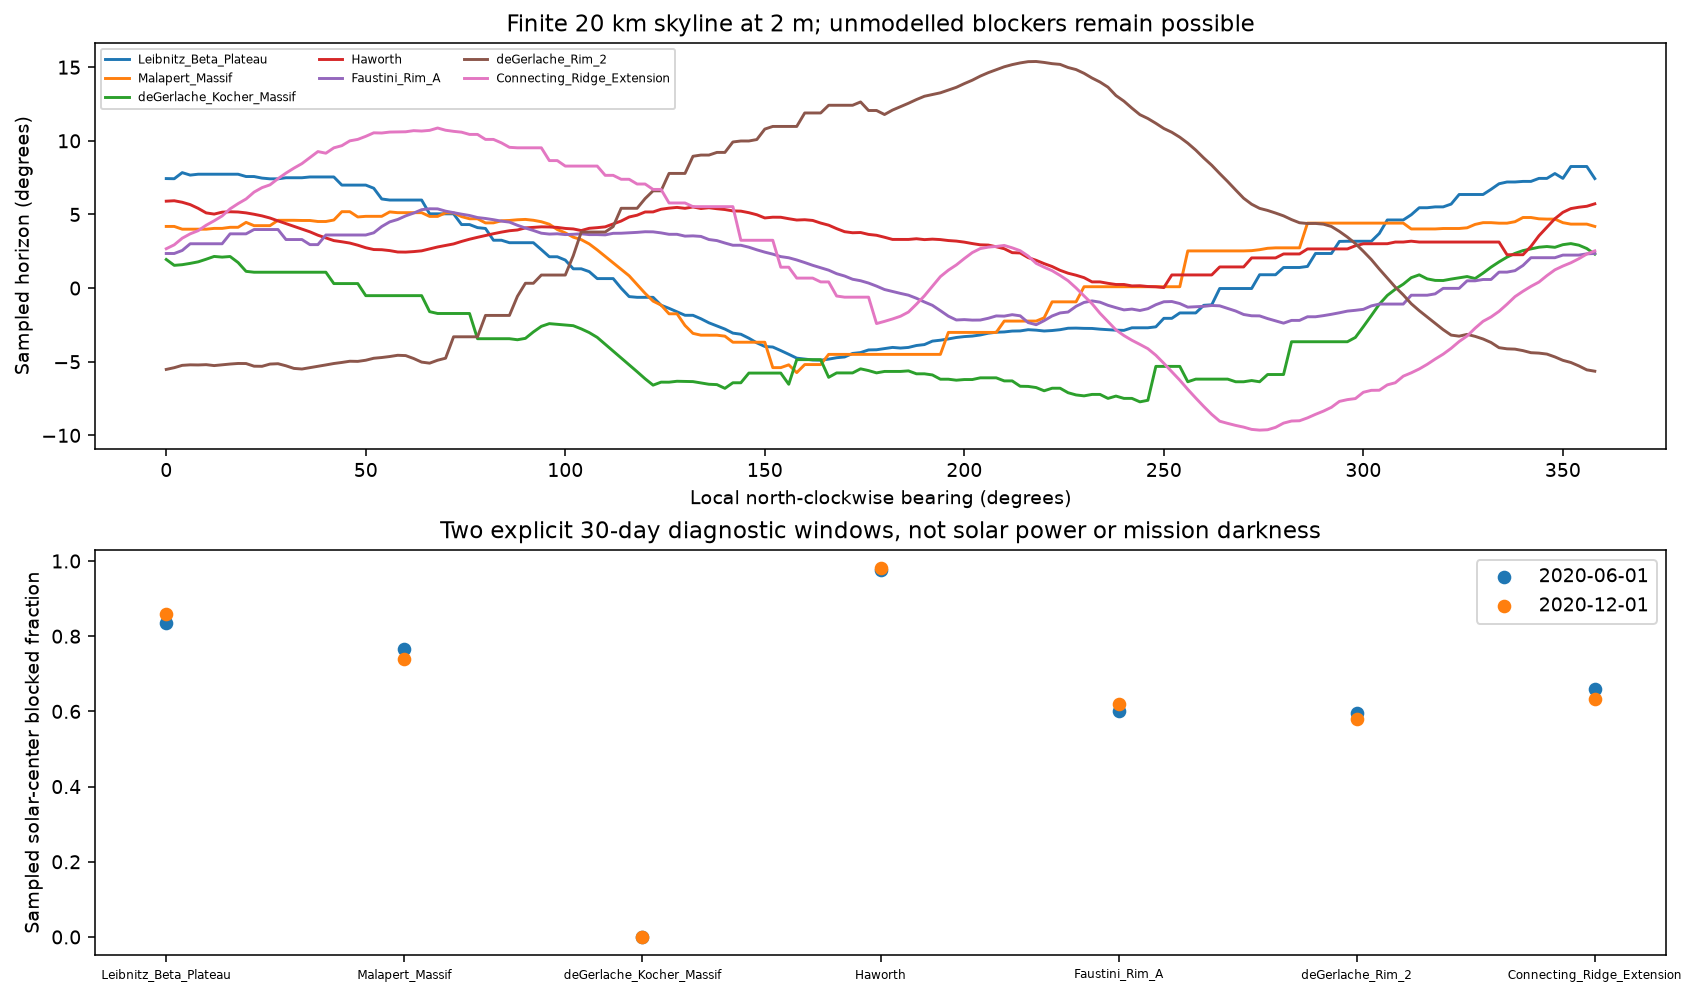

In [8]:
for picture in sorted(OUTPUT.glob('*.png')):
    display(Image(filename=str(picture)))

## Applicability
Preserve the measurement/model distinction, original units and spatial/temporal support. Missing mission, capability, requirement and hazard-response evidence remains Unknown. Later operational constraints must not be replaced by EDA score thresholds.